# Model Training and Evaluation

This is the stage 2 executable notebook. It picks up where stage 1 ends and starts from the verified files in `generated_output/`, constructs time-safe candidate tables, trains both recommender stages and runs the complete evaluation.



The notbook is different from the `Complete_Recommender_Pipeleine` its main use was for testing before combining the two stages so this must ONLY be ran after the `Stage1_generate_synthetic_dataset` file

## 1. Environment and paths

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
DATASET_ROOT = PROJECT_ROOT / "generated_output"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

required_source_files = [
    PROJECT_ROOT / "config.json",
    PROJECT_ROOT / "generate_dataset.py",
    PROJECT_ROOT / "build_two_stage_candidates.py",
    PROJECT_ROOT / "model_components.py",
    PROJECT_ROOT / "two_stage_recommender.py",
    PROJECT_ROOT / "validate_two_stage_outputs.py",
]
missing_source_files = [path.name for path in required_source_files if not path.exists()]
assert not missing_source_files, f"Missing project files: {missing_source_files}"

print("Project folder:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("Required source files found:", len(required_source_files))

Project folder: C:\Users\madma\Downloads\Complete 2 stage recommender system
Python: 3.14.4
Required source files found: 6


## 2. Verify the dataset-creation output

In [2]:
required_dataset_files = [
    DATASET_ROOT / "data/interactions.csv",
    DATASET_ROOT / "data/topics.csv",
    DATASET_ROOT / "data/resources.csv",
    DATASET_ROOT / "internal_generator_truth/candidate_potential_outcomes.csv",
    DATASET_ROOT / "validation/validation_summary.json",
]
missing_dataset_files = [
    str(path.relative_to(PROJECT_ROOT))
    for path in required_dataset_files
    if not path.exists()
]
assert not missing_dataset_files, (
    "Run Stage1_generate_synthetic_dataset.ipynb first. Missing: " + ", ".join(missing_dataset_files)
)

dataset_validation = json.loads(
    (DATASET_ROOT / "validation/validation_summary.json").read_text(
        encoding="utf-8"
    )
)
interactions = pd.read_csv(DATASET_ROOT / "data/interactions.csv")
dataset_summary = pd.DataFrame(
    [
        {"item": "topics", "value": dataset_validation["n_topics"]},
        {"item": "resources", "value": dataset_validation["n_resources"]},
        {"item": "learners", "value": dataset_validation["n_learners"]},
        {"item": "interactions", "value": dataset_validation["n_interactions"]},
        {
            "item": "observed score-gain targets",
            "value": dataset_validation["n_observed_score_gain_targets"],
        },
        {
            "item": "all dataset checks passed",
            "value": dataset_validation["all_checks_passed"],
        },
    ]
)
display(dataset_summary)
display(
    interactions.groupby("chronological_split", as_index=False)
    .agg(events=("interaction_id", "count"), learners=("learner_id", "nunique"))
)
assert dataset_validation["all_checks_passed"]

,item,value
0,topics,10
1,resources,40
2,learners,500
3,interactions,3957
4,observed score-gain targets,2279
5,all dataset checks passed,True


,chronological_split,events,learners
0,future_holdout,1008,500
1,train_history,2949,500


## Time-safe candidate construction

Each interaction is reconstructed as a decision point. All ten topics are compared for recommender Stage 1 and all 40 resources are represented for recommender Stage 2, with four resources attached to each topic. Only information available before the interaction is used as a predictor. Generator-known counterfactual outcomes are written to separate oracle tables and are used only for controlled evaluation.

In [3]:
from build_two_stage_candidates import save_candidate_tables

candidate_validation = save_candidate_tables(PROJECT_ROOT, DATASET_ROOT)
display(pd.DataFrame(candidate_validation.items(), columns=["check", "value"]))

required_candidate_checks = [
    "ten_topics_per_event",
    "forty_resources_per_event",
    "four_resources_per_event_topic",
    "one_selected_topic_per_event",
    "one_selected_resource_per_event",
    "all_original_selected_topic_oracles_matched",
    "graph_features_vary_across_topics",
]
assert all(candidate_validation[name] for name in required_candidate_checks)
assert not candidate_validation["prohibited_generator_truth_columns_in_public_tables"]

,check,value
0,events,3957
1,topic_candidate_rows,39570
2,resource_candidate_rows,158280
3,ten_topics_per_event,True
4,forty_resources_per_event,True
5,four_resources_per_event_topic,True
6,one_selected_topic_per_event,True
7,one_selected_resource_per_event,True
8,maximum_selected_score_state_difference,0.0
9,maximum_selected_mastery_state_difference,0.0


### Inspect one reconstructed decision

The selected flags show the historical action. They are audit and training-row indicators and are not predictors. The observed score gain is available only for the selected action when a post-assessment was recorded.

For an observed event (e), the supervised target is:

Y<sub>e</sub> = S<sub>e,post</sub> - S<sub>e,pre</sub>

where y<sub>e</sub> represents the observed score gain for interaction event e, S<sub>e,post</sub> represents the post-interaction score, and S<sub>e,pre</sub> represents the corresponding pre-interaction score.

In [4]:
topic_candidates = pd.read_csv(PROJECT_ROOT / "two_stage_data/topic_candidates.csv")
resource_candidates = pd.read_csv(PROJECT_ROOT / "two_stage_data/resource_candidates.csv")
candidate_dictionary = pd.read_csv(
    PROJECT_ROOT / "two_stage_data/two_stage_data_dictionary.csv"
)

example_event = topic_candidates["event_id"].iloc[0]
print("Topic candidate shape:", topic_candidates.shape)
print("Resource candidate shape:", resource_candidates.shape)
print("Example event:", example_event)

display(
    topic_candidates.loc[
        topic_candidates["event_id"].eq(example_event),
        [
            "candidate_topic_id",
            "current_score",
            "prerequisite_min_score",
            "unmet_prerequisite_count",
            "selected_topic_flag",
            "observed_score_gain",
        ],
    ]
)
display(
    resource_candidates.loc[
        resource_candidates["event_id"].eq(example_event)
        & resource_candidates["selected_topic_flag"].eq(1),
        [
            "candidate_resource_id",
            "resource_format_group",
            "resource_difficulty",
            "tfidf_cosine_similarity",
            "selected_resource_flag",
            "observed_score_gain",
        ],
    ]
)

Topic candidate shape: (39570, 42)
Resource candidate shape: (158280, 31)
Example event: E000001


,candidate_topic_id,current_score,prerequisite_min_score,unmet_prerequisite_count,selected_topic_flag,observed_score_gain
0,T01,25.0,100.0,0,0,NaN
1,T02,62.5,25.0,1,0,NaN
2,T03,25.0,25.0,1,0,NaN
3,T04,50.0,25.0,2,0,NaN
4,T05,62.5,25.0,1,0,NaN
5,T06,25.0,100.0,0,0,NaN
6,T07,0.0,25.0,2,1,0.0
7,T08,37.5,25.0,2,0,NaN
8,T09,50.0,100.0,0,0,NaN
9,T10,50.0,50.0,1,0,NaN


,candidate_resource_id,resource_format_group,resource_difficulty,tfidf_cosine_similarity,selected_resource_flag,observed_score_gain
24,R025,text,2,0.111605,0,NaN
25,R026,practice,2,0.096001,1,0.0
26,R027,text,3,0.059647,0,NaN
27,R028,text,3,0.082601,0,NaN


## Models and baselines

The comparison use simple baselines and learned models. Recommender Stage 1 compares random topic, weakest topic, prerequisite-ready weakness, Ridge and Random Forest. Recommender Stage 2 compares random resource, difficulty match, TF–IDF content similarity, biased matrix factorisation, Ridge and Random Forest.

Ridge estimates a regularised linear relationship:

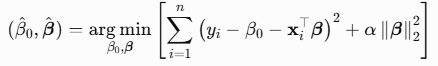

Here, y<sub>i</sub> is the observed score gain, x<sub>i</sub> is the feature vector, β<sub>0</sub> is the intercept, β contains the model coefficients, and α controls the strength of the penalty applied to large coefficients. The first term measures prediction error, while the second is the Ridge penalty.

This use of an (L<sub>2</sub>) penalty follows the statistical motivation in Hoerl and Kennard (1970). The collaborative baseline uses the biased factorisation form described by Koren, Bell and Volinsky (2009):


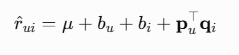

Here, r̂<sub>ui</sub> is the predicted score gain for learner u and resource i, μ is the global mean, b<sub>u</sub> and b<sub>i</sub> are the learner and resource biases, and p<sub>u</sub> and q<sub>i</sub> are their learned latent-factor vectors. Their dot product represents the estimated interaction between the learner’s preferences and the resource’s characteristics.


Separate Ridge models were fitted for the topic-ranking and resource-ranking stages. The value of α was selected through learner-grouped cross-validation rather than fixed arbitrarily

In [5]:
from two_stage_recommender import (
    PROHIBITED_TOKENS,
    RESOURCE_CATEGORICAL,
    RESOURCE_NUMERIC,
    TOPIC_CATEGORICAL,
    TOPIC_NUMERIC,
)

topic_predictors = TOPIC_NUMERIC + TOPIC_CATEGORICAL
resource_predictors = RESOURCE_NUMERIC + RESOURCE_CATEGORICAL
prohibited_topic_predictors = [
    name for name in topic_predictors
    if any(token in name.lower() for token in PROHIBITED_TOKENS)
]
prohibited_resource_predictors = [
    name for name in resource_predictors
    if any(token in name.lower() for token in PROHIBITED_TOKENS)
]

feature_summary = pd.DataFrame(
    [
        {
            "recommender_stage": "Stage 1 topic ranking",
            "predictor_count": len(topic_predictors),
            "prohibited_predictors": len(prohibited_topic_predictors),
        },
        {
            "recommender_stage": "Stage 2 resource ranking",
            "predictor_count": len(resource_predictors),
            "prohibited_predictors": len(prohibited_resource_predictors),
        },
    ]
)
display(feature_summary)
assert not prohibited_topic_predictors
assert not prohibited_resource_predictors

,recommender_stage,predictor_count,prohibited_predictors
0,Stage 1 topic ranking,36,0
1,Stage 2 resource ranking,23,0


## Training and evaluation

The final 20% of each learner's ordered history is held out for established-user evaluation. Hyperparameters are selected inside the earlier history using five-fold `GroupKFold`, with learner ID as the group so one learner cannot occur on both sides of a tuning fold. This is more defensible than a row-random split for repeated learner interactions.

The pipeline reports MAE, RMSE and (R^2) for observed score-gain prediction. Recommendation quality is assessed separately with NDCG, MRR, Precision@K, Recall@K, top-one accuracy and normalized regret. NDCG follows the cumulative-gain family by Järvelin and Kekäläinen (2002) and calculated with scikit-learn. 

Five repeated learner-level 80/20 splits assess first-event cold start. Each cold-start split repeats grouped tuning using only its 80% training learners. Fixed-model ablation, permutation importance, rule sensitivity and a paired Wilcoxon signed-rank comparison provide additional evidence

This takes a while


In [6]:
from two_stage_recommender import run_pipeline

results = run_pipeline(PROJECT_ROOT, DATASET_ROOT)
print("Model training and evaluation completed")
print("Established-user events:", results["validation"]["established_event_count"])
print("Cold-start splits:", results["validation"]["cold_start_splits"])

[1/6] Tuning and evaluating established-user models
[2/6] Running repeated unseen-learner evaluation
  Cold-start split 1/5: tuning on 400 learners
  Cold-start split 2/5: tuning on 400 learners
  Cold-start split 3/5: tuning on 400 learners
  Cold-start split 4/5: tuning on 400 learners
  Cold-start split 5/5: tuning on 400 learners
[3/6] Running fixed-model ablation
[4/6] Calculating importance, sensitivity and paired evidence
[5/6] Saving result tables and fitted models
[6/6] Saving figures and written summary
Model training and evaluation completed
Established-user events: 991
Cold-start splits: 5


## Hyperparameter selection and prediction results

In [7]:
tuning = json.loads(
    (PROJECT_ROOT / "two_stage_results/model_tuning.json").read_text(encoding="utf-8")
)
tuning_rows = []
for stage_name, stage_values in tuning.items():
    tuning_rows.append(
        {
            "stage": stage_name,
            "ridge_parameters": stage_values["ridge_best_parameters"],
            "ridge_grouped_cv_mae": stage_values["ridge_grouped_cv_mae"],
            "forest_parameters": stage_values["random_forest_best_parameters"],
            "forest_grouped_cv_mae": stage_values[
                "random_forest_grouped_cv_mae"
            ],
        }
    )
display(pd.DataFrame(tuning_rows))
display(results["topic_regression"])
display(results["resource_regression"])

,stage,ridge_parameters,ridge_grouped_cv_mae,forest_parameters,forest_grouped_cv_mae
0,topic_stage,{'model__alpha': 100.0},9.428780,"{'model__max_depth': 8, 'model__max_features':...",9.482699
1,resource_stage,{'model__alpha': 100.0},9.387534,"{'model__max_depth': 8, 'model__max_features':...",9.500320


,method,mae,rmse,r2
0,Random Forest,8.952855,11.350639,0.080530
1,Ridge,8.955229,11.205009,0.103972
2,Global mean,9.112013,11.926021,-0.015052


,method,mae,rmse,r2
0,Random Forest,8.945526,11.258203,0.095445
1,Ridge,8.972110,11.193169,0.105865
2,Global mean,9.112013,11.926021,-0.015052
3,Matrix factorization,10.568156,13.438918,-0.288919


## Ranking and end-to-end results

Stage-level results diagnose where performance is gained or lost. The end-to-end table is the decisive comparison because it measures the topic-resource pair actually returned by the complete system. Oracle rows are upper-bound diagnostics and are not deployable methods.

In [8]:
print("Recommender Stage 1: topic ranking")
display(results["topic_ranking"])

print("Recommender Stage 2: conditional resource ranking")
display(results["resource_ranking"])

print("End-to-end topic and resource pipelines")
display(results["end_to_end"])

Recommender Stage 1: topic ranking


,method,groups,ndcg_gain_at_5,ndcg_rank_at_5,top1_accuracy,mrr,precision_at_3,recall_at_3,normalized_regret,chosen_oracle_gain_points
0,Prerequisite-ready weakness,991,0.856481,0.705965,0.212159,0.408906,0.432223,0.432223,0.349125,6.092713
1,Random Forest topic,991,0.844508,0.685006,0.184662,0.386894,0.395896,0.395896,0.386973,5.940077
2,Weakest topic,991,0.855864,0.700067,0.164497,0.366431,0.412042,0.412042,0.422967,5.769814
3,Ridge topic,991,0.843186,0.682983,0.155399,0.370241,0.382778,0.382778,0.430000,5.738827
4,Random topic,991,0.798607,0.603653,0.109485,0.299149,0.302388,0.302388,0.514486,5.390270


Recommender Stage 2: conditional resource ranking


,method,groups,ndcg_gain_at_3,ndcg_rank_at_3,top1_accuracy,mrr,precision_at_2,recall_at_2,normalized_regret,chosen_oracle_gain_points
0,Difficulty match,991,0.983227,0.900509,0.598722,0.723920,0.830474,0.830474,0.102885,5.639776
1,Ridge resource,991,0.963632,0.841146,0.488396,0.705937,0.759839,0.759839,0.223755,5.455107
2,Random Forest resource,991,0.935524,0.736144,0.475277,0.664396,0.585772,0.585772,0.250421,5.467639
3,TF-IDF content,991,0.935316,0.762138,0.239152,0.520698,0.600908,0.600908,0.376741,5.027702
4,Random resource,991,0.904633,0.665289,0.246216,0.516313,0.499495,0.499495,0.486773,4.765756
5,Matrix factorization,991,0.905424,0.663289,0.244198,0.520266,0.492432,0.492432,0.518514,4.783087


End-to-end topic and resource pipelines


,pipeline,events,chosen_oracle_gain_points,normalized_regret,oracle_topic_hit_rate,oracle_pair_hit_rate
0,Oracle pair,991,7.572952,0.000000,1.000000,1.000000
1,Oracle topic + RF resource,991,6.908377,0.139402,1.000000,0.416751
2,Rule pipeline,991,5.883818,0.315256,0.215943,0.135217
3,RF topic + difficulty resource,991,5.746862,0.342400,0.184662,0.123108
4,RF two-stage,991,5.644720,0.369909,0.184662,0.103935
5,Ridge two-stage,991,5.448386,0.397253,0.155399,0.086781
6,Random pipeline,991,4.532333,0.564291,0.108981,0.025227


## Unseen-learner cold start

In [9]:
print("Stage 1 cold-start summary")
display(results["cold_topic"])

print("Stage 2 cold-start summary")
display(results["cold_resource"])

print("End-to-end cold-start summary")
display(results["cold_pipeline"])

print("Hyperparameters selected inside each cold-start training split")
display(results["cold_tuning"])

Stage 1 cold-start summary


,method,groups_mean,groups_sd,ndcg_gain_at_5_mean,ndcg_gain_at_5_sd,ndcg_rank_at_5_mean,ndcg_rank_at_5_sd,top1_accuracy_mean,top1_accuracy_sd,mrr_mean,mrr_sd,precision_at_3_mean,precision_at_3_sd,recall_at_3_mean,recall_at_3_sd,normalized_regret_mean,normalized_regret_sd,chosen_oracle_gain_points_mean,chosen_oracle_gain_points_sd
0,Prerequisite-ready weakness,100.0,0.0,0.883446,0.007085,0.765861,0.012775,0.329167,0.070917,0.503513,0.052291,0.508000,0.015741,0.508000,0.015741,0.230534,0.009019,7.106412,0.145650
3,Ridge topic,100.0,0.0,0.891175,0.007647,0.777388,0.012941,0.328000,0.037683,0.519016,0.021040,0.507333,0.012111,0.507333,0.012111,0.243712,0.016782,7.061037,0.151936
1,Random Forest topic,100.0,0.0,0.871971,0.008299,0.744126,0.014987,0.258000,0.080436,0.465627,0.052245,0.492667,0.027019,0.492667,0.027019,0.311031,0.043648,6.730233,0.206818
4,Weakest topic,100.0,0.0,0.888737,0.003542,0.762879,0.004806,0.245486,0.043408,0.441220,0.034317,0.510667,0.012338,0.510667,0.012338,0.326768,0.018947,6.630951,0.170497
2,Random topic,100.0,0.0,0.794084,0.013808,0.598727,0.014160,0.110000,0.029155,0.304340,0.021617,0.322000,0.012383,0.322000,0.012383,0.516947,0.032522,5.672120,0.175712


Stage 2 cold-start summary


,method,groups_mean,groups_sd,ndcg_gain_at_3_mean,ndcg_gain_at_3_sd,ndcg_rank_at_3_mean,ndcg_rank_at_3_sd,top1_accuracy_mean,top1_accuracy_sd,mrr_mean,mrr_sd,precision_at_2_mean,precision_at_2_sd,recall_at_2_mean,recall_at_2_sd,normalized_regret_mean,normalized_regret_sd,chosen_oracle_gain_points_mean,chosen_oracle_gain_points_sd
0,Difficulty match,100.0,0.0,0.985004,0.000960,0.907977,0.002184,0.630333,0.009006,0.745619,0.006408,0.860,0.028940,0.860,0.028940,0.089142,0.008658,6.115193,0.185674
4,Ridge resource,100.0,0.0,0.952776,0.012338,0.792978,0.033825,0.378000,0.086718,0.637667,0.050109,0.733,0.051430,0.733,0.051430,0.291104,0.093177,5.741390,0.149562
2,Random Forest resource,100.0,0.0,0.934783,0.005622,0.744365,0.022715,0.402000,0.046583,0.630833,0.024714,0.598,0.047645,0.598,0.047645,0.296025,0.067091,5.794656,0.188368
5,TF-IDF content,100.0,0.0,0.927089,0.005119,0.755035,0.016518,0.260000,0.050990,0.527238,0.037280,0.593,0.037014,0.593,0.037014,0.377241,0.029025,5.416364,0.191673
1,Matrix factorization,100.0,0.0,0.914917,0.004778,0.668783,0.026971,0.274000,0.042190,0.545333,0.029922,0.547,0.049447,0.547,0.049447,0.503169,0.045253,5.317526,0.166808
3,Random resource,100.0,0.0,0.900958,0.006673,0.677109,0.014869,0.242000,0.019235,0.517167,0.013650,0.507,0.020187,0.507,0.020187,0.515476,0.029873,5.118559,0.193756


End-to-end cold-start summary


,pipeline,events_mean,events_sd,chosen_oracle_gain_points_mean,chosen_oracle_gain_points_sd,normalized_regret_mean,normalized_regret_sd,oracle_topic_hit_rate_mean,oracle_topic_hit_rate_sd,oracle_pair_hit_rate_mean,oracle_pair_hit_rate_sd
0,Oracle pair,100.0,0.0,8.124514,0.107949,0.000000,0.000000,1.000,0.000000,1.000,0.000000
1,Oracle topic + RF resource,100.0,0.0,7.339117,0.176491,0.150194,0.020602,1.000,0.000000,0.430,0.040620
6,Rule pipeline,100.0,0.0,6.900261,0.141637,0.222711,0.007261,0.328,0.073959,0.182,0.050695
5,Ridge two-stage,100.0,0.0,6.575145,0.156204,0.272758,0.019525,0.328,0.037683,0.206,0.028810
2,RF topic + difficulty resource,100.0,0.0,6.388579,0.181179,0.300703,0.029806,0.258,0.080436,0.128,0.027749
3,RF two-stage,100.0,0.0,6.224026,0.233209,0.335143,0.043227,0.258,0.080436,0.150,0.060415
4,Random pipeline,100.0,0.0,4.709886,0.206833,0.578311,0.030881,0.110,0.029155,0.036,0.016733


Hyperparameters selected inside each cold-start training split


,split,seed,stage,training_learners,held_out_learners,ridge_alpha,ridge_grouped_cv_mae,forest_max_depth,forest_min_samples_leaf,forest_max_features,forest_grouped_cv_mae
0,1,3070,topic,400,100,100.0,9.136399,8,4,sqrt,9.242896
1,1,3070,resource,400,100,100.0,9.126324,8,4,sqrt,9.209689
2,2,3071,topic,400,100,100.0,9.289161,8,8,sqrt,9.347264
3,2,3071,resource,400,100,100.0,9.271705,8,4,sqrt,9.331920
4,3,3072,topic,400,100,100.0,9.124469,8,8,sqrt,9.212428
5,3,3072,resource,400,100,100.0,9.114277,8,4,sqrt,9.178345
6,4,3073,topic,400,100,100.0,9.287315,8,8,sqrt,9.362862
7,4,3073,resource,400,100,100.0,9.309965,8,8,sqrt,9.341335
8,5,3074,topic,400,100,100.0,9.354875,8,8,sqrt,9.453163
9,5,3074,resource,400,100,100.0,9.342320,8,4,sqrt,9.383875


## Ablation, importance and sensitivity

In [10]:
topic_importance = pd.read_csv(
    PROJECT_ROOT / "two_stage_results/topic_permutation_importance.csv"
)
resource_importance = pd.read_csv(
    PROJECT_ROOT / "two_stage_results/resource_permutation_importance.csv"
)

print("Topic-stage fixed-model ablation")
display(results["topic_ablation"])
print("Resource-stage fixed-model ablation")
display(results["resource_ablation"])
print("Largest topic-stage permutation effects")
display(topic_importance.head(10))
print("Largest resource-stage permutation effects")
display(resource_importance.head(10))
print("Declared rule-sensitivity scenarios")
display(results["sensitivity_summary"])

Topic-stage fixed-model ablation


,feature_set,mae,rmse,r2,ndcg_gain_at_5,ndcg_rank_at_5,top1_accuracy,mrr,precision_at_3,recall_at_3,normalized_regret,chosen_oracle_gain_points
0,No history,9.052875,11.476925,0.059956,0.858472,0.712029,0.221998,0.422258,0.417760,0.417760,0.349012,6.133103
1,No graph,8.955396,11.346231,0.081244,0.844984,0.685789,0.188698,0.391465,0.390178,0.390178,0.385489,5.955944
2,No resource catalogue,8.880501,11.265192,0.094321,0.846054,0.685847,0.181635,0.384373,0.388833,0.388833,0.386697,5.952911
3,Full topic model,8.952855,11.350639,0.080530,0.844508,0.685006,0.184662,0.386894,0.395896,0.395896,0.386973,5.940077
4,Performance only,8.895504,11.243720,0.097770,0.855730,0.699716,0.164497,0.366180,0.412378,0.412378,0.422967,5.769814


Resource-stage fixed-model ablation


,feature_set,mae,rmse,r2,ndcg_gain_at_3,ndcg_rank_at_3,top1_accuracy,mrr,precision_at_2,recall_at_2,normalized_regret,chosen_oracle_gain_points
0,Full resource model,8.945526,11.258203,0.095445,0.935524,0.736144,0.475277,0.664396,0.585772,0.585772,0.250421,5.467639
1,No interaction history,8.964009,11.317596,0.085876,0.927258,0.717142,0.393542,0.616381,0.538345,0.538345,0.351446,5.250669
2,No resource content,9.090573,11.383934,0.075128,0.909065,0.681047,0.291625,0.520030,0.587286,0.587286,0.419195,4.978894
3,Performance only,8.879378,11.235881,0.099028,0.905464,0.671249,0.250000,0.400000,0.640767,0.640767,0.490520,4.770087


Largest topic-stage permutation effects


,feature,mae_increase_mean,mae_increase_sd
0,weakness_score,0.106305,0.034426
1,current_score,0.093319,0.035409
2,topic_prior_mean_observed_gain,0.014851,0.005237
3,prior_mean_observed_gain,0.014712,0.014426
4,topic_prior_interaction_count,0.013831,0.019171
5,simulated_day,0.008606,0.010348
6,unmet_prerequisite_count,0.006494,0.002934
7,days_since_topic_interaction,0.006449,0.012442
8,prerequisite_min_score,0.004900,0.003453
9,prior_completion_rate,0.003414,0.006061


Largest resource-stage permutation effects


,feature,mae_increase_mean,mae_increase_sd
0,topic_current_score,0.067556,0.033045
1,topic_prior_interaction_count,0.046434,0.023613
2,topic_weakness,0.041284,0.027465
3,tfidf_cosine_similarity,0.036200,0.012244
4,candidate_topic_id,0.017367,0.014024
5,prior_mean_observed_gain,0.013420,0.010926
6,topic_curriculum_order,0.011150,0.010579
7,topic_prior_mean_observed_gain,0.005894,0.003762
8,simulated_day,0.003689,0.004719
9,desired_resource_difficulty,0.003640,0.028513


Declared rule-sensitivity scenarios


,pipeline,events,chosen_oracle_gain_points,normalized_regret,oracle_topic_hit_rate,oracle_pair_hit_rate,same_topic_as_default,same_resource_as_default
0,prereq_60__bands_45_75,991,5.883818,0.315256,0.215943,0.135217,1.000000,1.000000
1,prereq_70__bands_45_75,991,5.879399,0.317541,0.200807,0.130172,0.738648,0.738648
2,prereq_50__bands_45_75,991,5.829125,0.325430,0.200807,0.128153,0.805247,0.805247
3,prereq_50__bands_55_85,991,5.768771,0.338835,0.200807,0.117053,0.805247,0.680121
4,prereq_60__bands_55_85,991,5.765058,0.340781,0.215943,0.119072,1.000000,0.783047
5,prereq_70__bands_55_85,991,5.742709,0.345503,0.200807,0.115035,0.738648,0.574168
6,prereq_60__bands_35_65,991,5.349036,0.412962,0.215943,0.085772,1.000000,0.730575
7,prereq_50__bands_35_65,991,5.331224,0.417617,0.200807,0.085772,0.805247,0.583249
8,prereq_70__bands_35_65,991,5.291315,0.423961,0.200807,0.082745,0.738648,0.510595


## Paired statistical comparison

The comparison is performed on every learner's mean difference in normalized regret. 
A small p-value is evidence of a difference under this simulator; it is not evidence of improved learning for real CAPE students

In [11]:
paired_result = pd.DataFrame([results["paired_test"]])
display(paired_result)

,comparison,metric,learners,events,mean_difference,median_difference,wilcoxon_statistic,two_sided_p_value,direction,claim_boundary
0,RF two-stage vs Rule pipeline,per-learner mean normalized-regret difference,489,991,0.059547,0.0,29942.0,0.000001,Negative values favour RF two-stage; positive ...,Controlled simulator evidence only.


##  recommendations and educator-review protocol

In [12]:
sample_recommendations = pd.read_csv(
    PROJECT_ROOT / "two_stage_results/sample_recommendations.csv"
)
educator_review = results["educator_review"]

display(sample_recommendations)
print("Blinded synthetic cases prepared for adult educator review:", len(educator_review))
print("The blank review form is a protocol, not completed educator evidence")

,event_id,learner_id,recommended_topic,recommended_resource,topic_current_score,unmet_prerequisite_count,resource_difficulty,desired_resource_difficulty,tfidf_similarity,controlled_oracle_gain_points,explanation
0,E000006,L0001,File Processing,C Files,12.5,2,2,1,0.096001,6.146028,Topic score 12; 2 unmet prerequisites; resourc...
1,E000007,L0001,File Processing,C File Input/Output,12.5,1,2,1,0.111605,6.065035,Topic score 12; 1 unmet prerequisites; resourc...
2,E000014,L0002,Selection,C Conditions and If Statements,37.5,0,1,1,0.128842,6.379269,Topic score 38; 0 unmet prerequisites; resourc...
3,E000015,L0002,Selection,C Conditions and If Statements,37.5,0,1,1,0.128842,6.379269,Topic score 38; 0 unmet prerequisites; resourc...
4,E000022,L0003,Boolean Logic,C Operators,75.0,0,1,3,0.171098,5.238572,Topic score 75; 0 unmet prerequisites; resourc...


Blinded synthetic cases prepared for adult educator review: 10
The blank review form is a protocol, not completed educator evidence


## Final technical validation

In [13]:
from validate_two_stage_outputs import validate

technical_validation = validate(PROJECT_ROOT, DATASET_ROOT)
display(pd.DataFrame(technical_validation.items(), columns=["check", "value"]))
assert technical_validation["all_boolean_checks_passed"]

,check,value
0,event_count,3957
1,topic_candidate_row_count,39570
2,resource_candidate_row_count,158280
3,topic_candidate_count_correct,True
4,resource_candidate_count_correct,True
5,ten_topics_per_event,True
6,forty_resources_per_event,True
7,four_resources_per_event_topic,True
8,one_selected_topic_per_event,True
9,one_selected_resource_per_event,True


## Reproducibility record

Strts by storeing hashes of the deterministic modelling artefacts then clean rerun compares the new hashes with that baseline. This does not claim that different library versions or operating systems must create byte-identical serialized files.

In [14]:
from validate_two_stage_outputs import current_hashes

baseline_path = (
    PROJECT_ROOT / "two_stage_results/reproducibility_baseline_hashes.json"
)
current = current_hashes(PROJECT_ROOT)

if baseline_path.exists():
    previous = json.loads(baseline_path.read_text(encoding="utf-8"))
    mismatches = sorted(
        path for path in set(previous) | set(current)
        if previous.get(path) != current.get(path)
    )
    print("Files compared:", len(current))
    print("Byte-identical to stored baseline:", not mismatches)
    if mismatches:
        print("Mismatches:", mismatches)
else:
    baseline_path.write_text(
        json.dumps(current, indent=2, sort_keys=True),
        encoding="utf-8",
    )
    print("Saved the first reproducibility baseline:", baseline_path.name)

Files compared: 30
Byte-identical to stored baseline: True


## Interpretation boundary

The completed pipeline shows reproducible data ingestion, preprocessing, supervised modelling, content-based and collaborative baselines, two-stage recommendation, grouped tuning, chronological testing, cold-start testing, multiple ranking measures, statistical comparison and inspectable outputs. These are controlled results against a disclosed simulator. The rule baseline is also closely aligned with the simulator's weakness, prerequisite and difficulty assumptions, so its performance may parlty reflect generator structure. The notebook cannot establish knowledge retention, learning efficiency or benefit to real CAPE learners without ethically collected real-world data and a prospective evaluation